# Hình 3 — Chi tiết các khối HNF, FiLM và self-attention

Notebook Colab **vẽ sơ đồ phương pháp**, không huấn luyện hoặc đánh giá mô hình. Mã vẽ được nhúng đầy đủ; không cần GPU, dataset, checkpoint, ảnh gốc hoặc thư mục `src`.

**Cách dùng:** Colab CPU → **Run all**. Xem từng phần ở **6a, 6b, 6c**, bản ghép ở **mục 7**. Không tự tải file. Khi chốt, bật xuất tại **mục 8** để lấy `3.png`, `3.pdf`, `3.svg`; có thể xuất thêm `3a`, `3b`, `3c`.

- **(a) HNF:** bốn nhánh Conv1D đa tỉ lệ, half instance normalization và residual.
- **(b) FiLM:** embedding mức diffusion → Linear → SiLU → scale/shift theo kênh.
- **(c) Self-attention:** tạo Q/K/V, chia head, attention theo thời gian và chiếu đầu ra.

Mỗi phần có luồng chính từ trên xuống. Bản ghép đặt ba phần cạnh nhau, khổ hai cột IEEE **7.16 × 4.8 inch**, không giảm cỡ chữ khi ghép. Cấu hình và phép tính được đối chiếu với **U4 mix 512**; các lớp trong `src` và notebook huấn luyện đã được kiểm tra khớp AST khi tạo notebook này.


## 1. Nội dung cần đọc đúng

**HNF:** mỗi nhánh kernel $3,5,9,15$ sinh $C_o/4$ kênh, dùng reflection padding để giữ chiều dài. Sau nối là Conv1D kernel 1, chia đôi kênh, chỉ InstanceNorm nửa đầu, nối lại rồi ReLU. **Residual cộng sau ReLU**; nhánh tắt là Identity hoặc Conv1D kernel 1 khi đổi số kênh.

**FiLM:** $s=\sqrt{\bar\alpha}$ → embedding hình sin 128 chiều → Linear $128\to2C$ → SiLU → chia thành $\gamma(s),\xi(s)$. Công thức:

\[
h'=h\odot(1+\gamma(s))+\xi(s).
\]

Scale/shift theo kênh và broadcast theo chiều thời gian. FiLM nằm tại bốn encoder, không nằm tại decoder hoặc trên nhánh skip.

**Self-attention:** ví dụ bottleneck U4 có $640\times64$, chia 4 head nên $d_h=160$. Trong công thức hiển thị, mỗi $Q_h,K_h,V_h$ được hiểu theo dạng $L_b\times d_h$:

\[
A_h=\operatorname{softmax}(Q_hK_h^T/\sqrt{d_h}),\qquad O_h=A_hV_h.
\]

Nối 4 head và Conv1D kernel 1 để chiếu đầu ra. Không thêm lớp norm, dropout hoặc residual bao ngoài vì mã nguồn hiện hành không có. Kích thước 640 × 64 là kích thước kiến trúc cho đoạn 512, không phải kết quả đo.


## 2. Cấu hình hình

Có thể chỉnh màu, cỡ chữ, độ nét và khổ hình. `FONT_SCALE` dùng chung cho bản riêng/bản ghép; không tự thu nhỏ chữ. `GRAYSCALE=True` xem bản xám. Khi thay chữ khiến vượt khung, hãy tăng khung/ngắt dòng. Chế độ mặc định không tạo thư mục hoặc tải file.

In [1]:
from pathlib import Path
from io import BytesIO
import json
import zipfile
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, Rectangle
from matplotlib.path import Path as MplPath
from IPython.display import display, Image

COMBINED_WIDTH_IN, COMBINED_HEIGHT_IN = 7.16, 4.8
PANEL_WIDTH_IN, PANEL_HEIGHT_IN = 3.5, 5.2
FONT_SCALE = 1.0
PREVIEW_DPI, PNG_DPI = 160, 600
GRAYSCALE = False
STRICT_TEXT_CHECK = True
PANEL_BOUNDS = {'a': (0, 5.35), 'b': (5.35, 10.45), 'c': (10.45, 16)}
INK, MUTED = '#233240', '#526171'
BLUE, GOLD = '#245A81', '#8C651F'
HNF_FILL, FILM_FILL, ATTN_FILL = '#E9F1F7', '#FBF2DD', '#F0EBF5'
GRAY_FILL, WHITE = '#F4F6F8', '#FFFFFF'
if GRAYSCALE:
    BLUE = GOLD = INK
    HNF_FILL, FILM_FILL, ATTN_FILL = '#E7E7E7', '#F4F4F4', '#DADADA'
plt.rcParams.update({
    'font.family': 'DejaVu Serif', 'font.size': 8.2, 'mathtext.fontset': 'dejavuserif',
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
    'svg.hashsalt': 'ecg-u4-fig03', 'savefig.facecolor': WHITE, 'axes.unicode_minus': False,
})
OUTPUT_DIR = (Path('/content') if Path('/content').exists() else Path.cwd()) / 'fig03_blocks'
SOURCE_BLOCK_SHA256 = {'HNFBlock': '33862865ce69eb53930ded3370905356e29f13269bbc280a98072196b4277886', 'BridgeBlock': '038a6c7fddc9c38c42c2bc87bf906cc7715982ca29308ce5dc9106d0e8fbff9c', 'SelfAttention1D': 'b13bd7d412ef3d5ffc917c69aa8df2bc86dba35c75f69baa5e42d8ffd3e6077c'}
print('Matplotlib:', matplotlib.__version__)
print('Chỉ xem hình trong notebook; chưa xuất hoặc tải file.')


Matplotlib: 3.11.0
Chỉ xem hình trong notebook; chưa xuất hoặc tải file.


## 3. Hàm vẽ và kiểm tra bố cục

In [2]:
def canvas(width: float, height: float, xmax: float, ymax: float):
    fig = plt.figure(figsize=(width, height), facecolor=WHITE)
    ax = fig.add_axes((0.008, 0.012, 0.984, 0.976))
    ax.set(xlim=(0, xmax), ylim=(0, ymax))
    ax.axis("off")
    return fig, ax


def label(ax, x, y, text, *, size=8.2, color=INK, weight="normal",
          ha="center", va="center", rotation=0):
    return ax.text(x, y, text, fontsize=size * FONT_SCALE, color=color, fontweight=weight,
                   ha=ha, va=va, rotation=rotation, linespacing=1.28,
                   zorder=6)


def box(ax, x, y, width, height, text, *, fill=GRAY_FILL,
        edge=INK, size=8.2, weight="normal"):
    patch = Rectangle((x - width / 2, y - height / 2), width, height,
                      linewidth=0.75, edgecolor=edge, facecolor=fill, zorder=3)
    ax.add_patch(patch)
    artist = label(ax, x, y, text, size=size, weight=weight)
    if not hasattr(ax.figure, "_diagram_box_labels"):
        ax.figure._diagram_box_labels = []
    ax.figure._diagram_box_labels.append((patch, artist))
    return {"left": (x-width/2, y), "right": (x+width/2, y),
            "top": (x, y+height/2), "bottom": (x, y-height/2),
            "center": (x, y)}


def circle(ax, x, y, text, *, radius=0.17, color=INK, size=9):
    ax.add_patch(Circle((x, y), radius, facecolor=WHITE,
                        edgecolor=color, linewidth=0.8, zorder=4))
    label(ax, x, y, text, size=size)
    return {"left": (x-radius, y), "right": (x+radius, y),
            "top": (x, y+radius), "bottom": (x, y-radius),
            "center": (x, y)}


def arrow(ax, points, *, color=INK, dashed=False, width=0.8,
          head=7.5, zorder=2):
    codes = [MplPath.MOVETO] + [MplPath.LINETO] * (len(points) - 1)
    ax.add_patch(FancyArrowPatch(path=MplPath(points, codes),
                                 arrowstyle="-|>", mutation_scale=head,
                                 linewidth=width, color=color,
                                 linestyle=(0, (3, 2)) if dashed else "solid",
                                 zorder=zorder, shrinkA=0, shrinkB=0))


def line(ax, points, *, color=INK, dashed=False, width=0.75):
    xs, ys = zip(*points)
    ax.plot(xs, ys, color=color, linewidth=width,
            linestyle=(0, (3, 2)) if dashed else "solid", zorder=1)


def check_diagram(fig):
    """Catch out-of-box text and labels outside the canvas at actual print size."""
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    warnings = []
    for patch, artist in getattr(fig, '_diagram_box_labels', []):
        frame = patch.get_window_extent(renderer)
        text = artist.get_window_extent(renderer)
        if (text.x0 < frame.x0 + 1 or text.x1 > frame.x1 - 1
                or text.y0 < frame.y0 + 1 or text.y1 > frame.y1 - 1):
            warnings.append('Chữ vượt khối: ' + artist.get_text().replace('\n', ' / '))
    boxes = getattr(fig, '_diagram_box_labels', [])
    for index, (first, first_text) in enumerate(boxes):
        first_box = first.get_window_extent(renderer)
        for second, second_text in boxes[index + 1:]:
            second_box = second.get_window_extent(renderer)
            width = min(first_box.x1, second_box.x1) - max(first_box.x0, second_box.x0)
            height = min(first_box.y1, second_box.y1) - max(first_box.y0, second_box.y0)
            if width > 0.5 and height > 0.5:
                warnings.append('Hai khối chồng nhau: '
                                + first_text.get_text().replace('\n', ' / ') + ' & '
                                + second_text.get_text().replace('\n', ' / '))
    bounds = fig.bbox
    for axis in fig.axes:
        for artist in axis.texts:
            text = artist.get_window_extent(renderer)
            if (text.x0 < bounds.x0 or text.x1 > bounds.x1
                    or text.y0 < bounds.y0 or text.y1 > bounds.y1):
                warnings.append('Chữ vượt canvas: ' + artist.get_text().replace('\n', ' / '))
    for warning in warnings:
        print(warning)
    if warnings and STRICT_TEXT_CHECK:
        raise ValueError('Cần chỉnh khung/ngắt dòng hoặc tăng kích thước hình.')
    if not warnings:
        print('Kiểm tra chữ: nằm trong khung và canvas.')
    return warnings

## 4. Phần (a) — HNF

Sửa nhãn, khung hoặc đường nối của HNF trong cell dưới. Hình dùng ký hiệu tổng quát $C_i,C_o,L$ vì cùng khối được dùng ở nhiều mức encoder/decoder.

In [3]:
def draw_panel_a(ax):
    label(ax, 2.75, 8.08, "(a) Khối HNF", size=8.4, weight="bold")
    h = box(ax, 2.75, 7.35, 1.75, 0.48, r"$h$: $C_i\times L$", fill=WHITE)
    convs = []
    for x, kernel in zip((1.00, 2.15, 3.3, 4.45), (3, 5, 9, 15)):
        node = box(ax, x, 6.12, 1.02, 0.66,
                   "Conv1D\n" + rf"$k={kernel}$", fill=HNF_FILL, size=7.5)
        convs.append(node)
        arrow(ax, [h["bottom"], (2.75, 6.8), (x, 6.8), node["top"]])
    concat = box(ax, 2.75, 5.08, 2.05, 0.48, "Concat: " + r"$C_o\times L$")
    for node in convs:
        x = node["center"][0]
        arrow(ax, [node["bottom"], (x, 5.55), (2.75, 5.55), concat["top"]])
    agg = box(ax, 2.75, 4.27, 2.05, 0.48, "Conv1D " + r"$k=1$", fill=HNF_FILL)
    arrow(ax, [concat["bottom"], agg["top"]])
    norm = box(ax, 1.55, 3.25, 1.9, 0.68,
               "InstanceNorm\n" + r"$C_o/2$" + " kênh", fill=HNF_FILL, size=7.6)
    identity = box(ax, 4.0, 3.25, 1.9, 0.68,
                   "Identity\n" + r"$C_o/2$" + " kênh", fill=WHITE, size=7.6)
    for node in (norm, identity):
        arrow(ax, [agg["bottom"], (2.75, 3.83),
                   (node["center"][0], 3.83), node["top"]])
    concat2 = box(ax, 2.75, 2.22, 2.05, 0.48, "Concat")
    for node in (norm, identity):
        arrow(ax, [node["bottom"], (node["center"][0], 2.66),
                   (2.75, 2.66), concat2["top"]])
    relu = box(ax, 2.75, 1.4, 1.6, 0.48, "ReLU")
    add = circle(ax, 2.75, 0.68, "+", radius=0.17)
    arrow(ax, [concat2["bottom"], relu["top"]])
    arrow(ax, [relu["bottom"], add["top"]])
    arrow(ax, [h["left"], (0.18, 7.35), (0.18, 0.68), add["left"]])
    label(ax, 0.34, 3.45, "Residual: Identity / Conv1D k=1", rotation=90, size=7.5)
    label(ax, 3.82, 0.64, r"$\mathcal{H}(h)$", size=9)
    arrow(ax, [add["right"], (3.3, 0.68)])
    label(ax, 2.75, 0.19, "Mỗi nhánh Conv1D sinh " + r"$C_o/4$" + " kênh.", size=7.3)

## 5. Phần (b), (c) — FiLM và self-attention

Hai hàm được tách thành hai cell để chỉnh riêng. Ký hiệu shift dùng $\xi$ để không nhầm với nhiễu Gaussian $\epsilon$.

In [4]:
def draw_panel_b(ax):
    label(ax, 7.9, 8.08, "(b) Điều chế FiLM", size=8.4, weight="bold")
    s = box(ax, 7.95, 7.35, 1.5, 0.48, r"$s=\sqrt{\bar\alpha}$", fill=WHITE)
    emb = box(ax, 7.95, 6.34, 3.85, 0.72,
              "Sinusoidal embedding\n128 chiều", fill=FILM_FILL)
    proj = box(ax, 7.95, 5.27, 3.85, 0.72,
               "Linear: " + r"$128\rightarrow2C$" + "\nSiLU", fill=FILM_FILL)
    arrow(ax, [s["bottom"], emb["top"]])
    arrow(ax, [emb["bottom"], proj["top"]])
    gamma = box(ax, 6.82, 4.13, 1.65, 0.55, r"$\gamma(s)$", fill=FILM_FILL, size=9)
    shift = box(ax, 9.07, 4.13, 1.65, 0.55, r"$\xi(s)$", fill=FILM_FILL, size=9)
    for node in (gamma, shift):
        arrow(ax, [proj["bottom"], (7.95, 4.72),
                   (node["center"][0], 4.72), node["top"]])
    scale = box(ax, 6.82, 3.13, 1.65, 0.55, r"$1+\gamma(s)$", fill=FILM_FILL)
    arrow(ax, [gamma["bottom"], scale["top"]])
    product = circle(ax, 6.82, 2.08, r"$\times$", radius=0.18)
    summation = circle(ax, 8.15, 2.08, "+", radius=0.18)
    label(ax, 5.82, 2.08, r"$h$", size=10)
    arrow(ax, [(6.0, 2.08), product["left"]])
    arrow(ax, [scale["bottom"], product["top"]])
    arrow(ax, [product["right"], summation["left"]])
    arrow(ax, [shift["bottom"], (9.07, 2.69), (8.15, 2.69), summation["top"]])
    arrow(ax, [summation["right"], (9.3, 2.08)])
    label(ax, 9.65, 2.08, r"$h'$", size=10)
    label(ax, 7.95, 1.07, r"$h'=h\odot(1+\gamma(s))+\xi(s)$", size=8.2)
    label(ax, 7.95, 0.45, "Scale và shift theo kênh,\nbroadcast trên chiều thời gian.", size=7.5)

In [5]:
def draw_panel_c(ax):
    label(ax, 13.25, 8.08, "(c) Self-attention", size=8.4, weight="bold")
    e4 = box(ax, 13.13, 7.35, 2.45, 0.48, r"$e_4$: $640\times64$", fill=WHITE)
    qkv = box(ax, 13.13, 6.34, 3.65, 0.72,
              "Conv1D " + r"$k=1$" + "\nTạo Q, K, V", fill=ATTN_FILL)
    heads = box(ax, 13.13, 5.27, 3.65, 0.72,
                "Chia 4 head\n" + r"$d_h=160$", fill=ATTN_FILL)
    weights = box(ax, 13.13, 4.13, 3.9, 0.68,
                  r"$A_h=\mathrm{softmax}(Q_hK_h^T/\sqrt{d_h})$", fill=ATTN_FILL, size=8)
    av = box(ax, 13.13, 3.02, 3.15, 0.55,
             r"$O_h=A_hV_h$", fill=ATTN_FILL)
    join = box(ax, 13.13, 2.09, 3.65, 0.55, "Nối kết quả 4 head")
    projection = box(ax, 13.13, 1.16, 3.65, 0.68,
                     "Conv1D " + r"$k=1$" + "\nChiếu đầu ra", fill=ATTN_FILL)
    for upper, lower in zip((e4, qkv, heads, weights, av, join),
                             (qkv, heads, weights, av, join, projection)):
        arrow(ax, [upper["bottom"], lower["top"]])
    arrow(ax, [heads["right"], (15.58, 5.27), (15.58, 3.02), av["right"]])
    label(ax, 15.64, 4.99, r"$V_h$", size=7.8, ha="left")
    label(ax, 13.52, 4.72, r"$Q_h,K_h$", size=7.2, ha="left")
    label(ax, 13.13, 0.45, "Đầu ra 640 × 64\n(kích thước minh họa với L = 512)", size=7.4)

## 6. Chuẩn bị xem riêng từng phần

Chạy cell định nghĩa dưới một lần. Sau khi sửa phần nào, chạy lại hàm vẽ của phần đó rồi chỉ chạy cell xem tương ứng 6a/6b/6c.

In [6]:
def make_blocks_figure(panel=None):
    draws = {'a': draw_panel_a, 'b': draw_panel_b, 'c': draw_panel_c}
    if panel is not None and panel not in draws:
        raise ValueError('panel phải là a, b, c hoặc None cho bản ghép.')
    width = COMBINED_WIDTH_IN if panel is None else PANEL_WIDTH_IN
    height = COMBINED_HEIGHT_IN if panel is None else PANEL_HEIGHT_IN
    fig, ax = canvas(width, height, 16, 8.35)
    try:
        if panel is None:
            for draw in draws.values():
                draw(ax)
            for x in (5.35, 10.45):
                line(ax, [(x, 0.18), (x, 8.0)], color='#CBD2D9', width=0.5)
        else:
            ax.set_xlim(*PANEL_BOUNDS[panel])
            draws[panel](ax)
        check_diagram(fig)
        return fig
    except Exception:
        plt.close(fig)
        raise

def preview_blocks(panel=None):
    fig = make_blocks_figure(panel)
    try:
        with BytesIO() as buffer:
            fig.savefig(buffer, format='png', dpi=PREVIEW_DPI)
            display(Image(data=buffer.getvalue()))
    finally:
        plt.close(fig)


### 6a. Xem riêng HNF

Kiểm tra chữ: nằm trong khung và canvas.


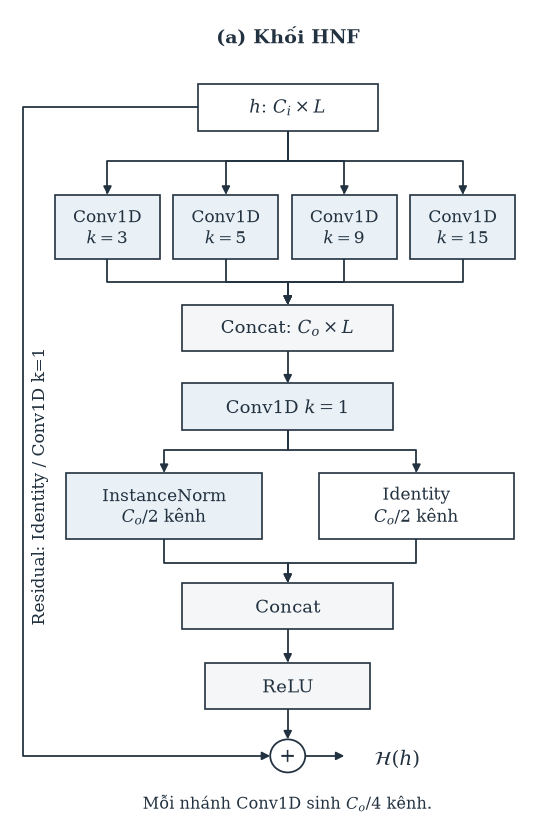

In [7]:
preview_blocks('a')

### 6b. Xem riêng FiLM

Kiểm tra chữ: nằm trong khung và canvas.


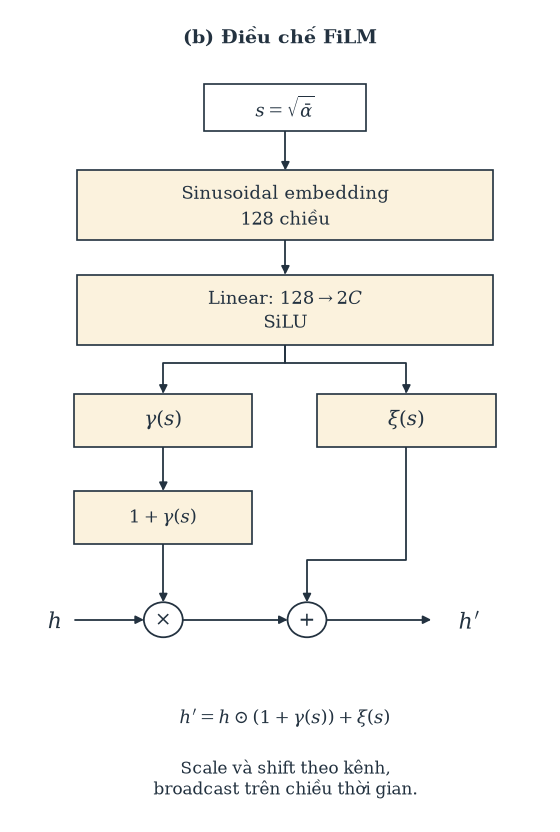

In [8]:
preview_blocks('b')

### 6c. Xem riêng self-attention

Kiểm tra chữ: nằm trong khung và canvas.


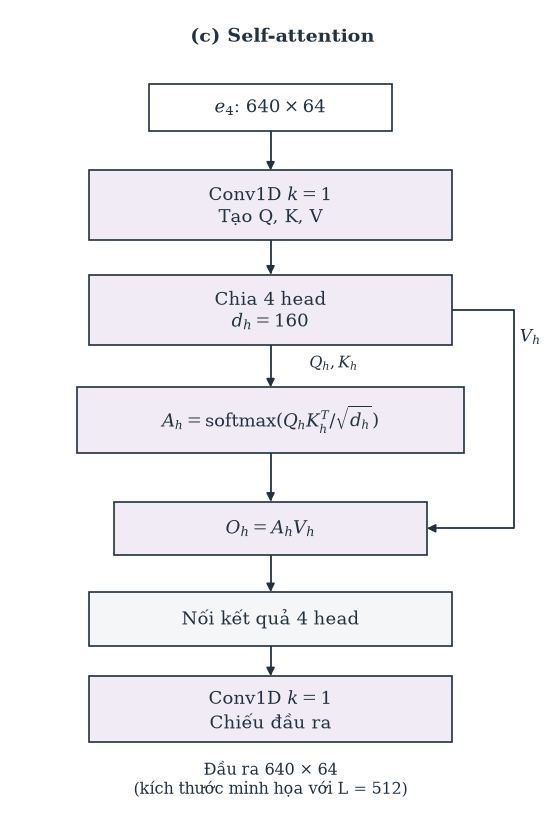

In [9]:
preview_blocks('c')

## 7. Xem Hình 3 hoàn chỉnh

Bản ghép dùng cùng hàm vẽ với bản riêng, không cắt/dán ảnh raster. Xem ở khổ hai cột paper trước khi xuất.

Kiểm tra chữ: nằm trong khung và canvas.


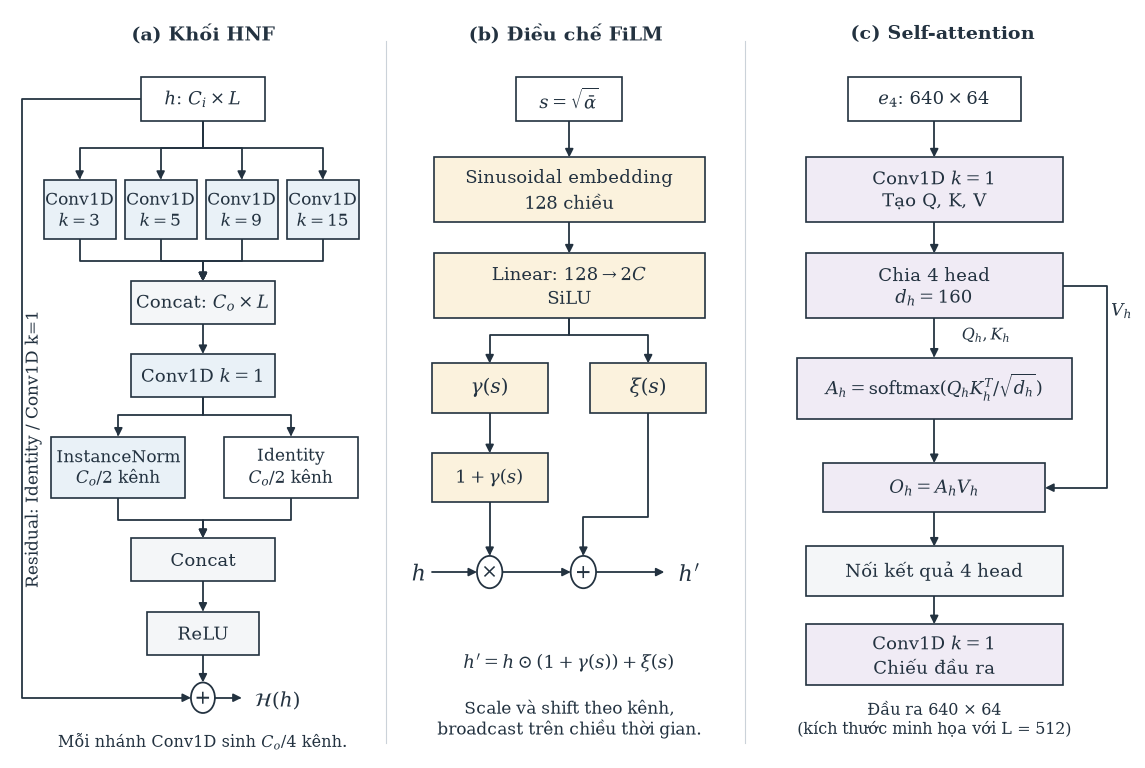

In [10]:
preview_blocks()

## 8. Xuất và tải — tùy chọn

Mặc định Run all **không xuất hoặc tải file**. Đặt `EXPORT_FILES=True` rồi chạy riêng cell này khi đã chốt. `EXPORT_PANELS=True` xuất thêm ba phần riêng. Chỉ bật `DOWNLOAD_ZIP=True` nếu muốn tải ZIP về máy. Bản ghép có tên **3.png / 3.pdf / 3.svg**, các bản riêng là 3a/3b/3c.

In [11]:
EXPORT_FILES = False
DOWNLOAD_ZIP = False
EXPORT_PANELS = True

def export_blocks():
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    paths = []
    for panel in ([None, 'a', 'b', 'c'] if EXPORT_PANELS else [None]):
        fig = make_blocks_figure(panel)
        try:
            basename = '3' if panel is None else f'3{panel}'
            for extension in ('pdf', 'svg', 'png'):
                target = OUTPUT_DIR / f'{basename}.{extension}'
                options = {}
                if extension == 'pdf':
                    options['metadata'] = {'Title': basename, 'CreationDate': None, 'ModDate': None}
                elif extension == 'svg':
                    options['metadata'] = {'Date': None}
                else:
                    options['dpi'] = PNG_DPI
                fig.savefig(target, **options)
                paths.append(target)
        finally:
            plt.close(fig)
    spec_path = OUTPUT_DIR / 'figure_specification.json'
    spec_path.write_text(json.dumps({
        'kind': 'method_diagram_not_experimental_result', 'figure': 3,
        'source_notebook': 'kaggle_ablation_u4_all_noise_512_100ep.ipynb',
        'source_block_sha256': SOURCE_BLOCK_SHA256,
        'panels': {'a': 'HNF', 'b': 'FiLM', 'c': 'self_attention'},
        'combined_inches': [COMBINED_WIDTH_IN, COMBINED_HEIGHT_IN],
        'separate_inches': [PANEL_WIDTH_IN, PANEL_HEIGHT_IN],
        'font_scale': FONT_SCALE, 'png_dpi': PNG_DPI, 'grayscale': GRAYSCALE,
    }, ensure_ascii=False, indent=2), encoding='utf-8')
    paths.append(spec_path)
    zip_path = OUTPUT_DIR / 'fig03_blocks.zip'
    with zipfile.ZipFile(zip_path, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
        for path in paths:
            archive.write(path, arcname=path.name)
    print('Đã xuất:', ', '.join(path.name for path in paths))
    print('ZIP:', zip_path)
    return zip_path

if EXPORT_FILES:
    zip_path = export_blocks()
    if DOWNLOAD_ZIP:
        try:
            from google.colab import files
        except ImportError:
            print('Ngoài Colab: mở ZIP theo đường dẫn trên.')
        else:
            files.download(str(zip_path))
else:
    print('Chỉ xem trong notebook; chưa xuất/tải file.')


Chỉ xem trong notebook; chưa xuất/tải file.


## 9. Chèn vào Overleaf bằng tên file

Tải `3.png` lên thư mục gốc dự án Overleaf; dùng trực tiếp **`{3.png}`**, không ghi đường dẫn máy tính. PDF vector có thể dùng bằng cách đổi thành `{3.pdf}`. Đường dẫn thư mục chỉ dành cho nơi lưu bản cục bộ, không cần trong câu lệnh chèn ảnh Overleaf.

```latex
\begin{figure*}[t]
  \centering
  \includegraphics[width=\textwidth]{3.png}
  \caption{Các khối thành phần: (a) HNF đa tỉ lệ, chuẩn hóa nửa số kênh
  và cộng residual sau ReLU; (b) FiLM điều chế affine theo mức khuếch tán;
  (c) self-attention bốn head tại bottleneck, không có residual bao ngoài.}
  \label{fig:blocks}
\end{figure*}
```

Notebook không tự sửa paper hoặc thay ảnh Hình 1/2. Kiểm tra nhánh residual HNF, phép $1+\gamma$, vị trí SiLU và nhánh $V_h$ trước khi chốt. Khi thay cỡ chữ, chạy lại từ cấu hình để bản riêng và bản ghép thống nhất.
